# Phase 0 — Data and classical baselines (v3)
**Project:** Connectivity-aware projected quantum kernels for distribution-shifted intrusion detection

Datasets in this version: **UNSW-NB15** (official CSVs), **NF-UNSW-NB15-v2** (Kaggle-cleaned Parquet) and **Fashion-MNIST** (official idx files, T-shirt/top vs Shirt). NF-ToN-IoT-v2 remains supported but is off by default.

Design decisions, made after auditing the actual files:
* reads NetFlow data as **Parquet** (the Kaggle-cleaned copies) **or CSV** (the UQ originals), and accepts the folder names exactly as they come out of the zip files;
* **deduplicates each NetFlow dataset globally before sampling and splitting.** Once ports and DNS IDs are removed, about 95% of NF-UNSW-NB15-v2 rows and 92% of NF-ToN-IoT-v2 rows are exact repeats, so a split on raw rows would put identical flows in train and test;
* labels each unique flow by **majority vote** over its copies, and drops only vectors that are ambiguous between benign and attack;
* uses only the **official Fashion-MNIST idx files** (hash-checked against Zalando's release); the widely shared CSV versions place thousands of official training images in their test file and are ignored;
* evaluates UNSW-NB15 on a **clean test set** (deduplicated, no vector also seen in training) and also on the **official test set**, so the effect of the official split's overlap is measured rather than hidden.

| Step | What it does | Checkpoint you confirm |
|---|---|---|
| 1 | Config, environment record | Paths and mode printed |
| 2 | Locate raw files, SHA-256 manifest | Every dataset `FOUND`; hashes compared with the audited files |
| 3 | NetFlow pass 1: stream to Parquet parts, hash every feature vector | Row and attack counts match a known source |
| 4 | Global deduplication, majority labels, reproducible sample | Per-class table of rows → unique → sampled |
| 5 | UNSW-NB15 (deduplicated train, clean and official test) and the Fashion-MNIST pair | Overlap counts printed; pair sizes 12,000 / 2,000 |
| 6 | Splits with zero train/test vector overlap | Overlap assertion passes |
| 7 | Leakage audit: single-feature probes + TTL ablation (C4) | Flagged features listed, TTL decision |
| 8 | Preprocessing fitted on train only | Feature counts |
| 9 | Feature sets: F8–F24 for network data, PCA 8–24 for Fashion-MNIST | Rankings and PCA saved |
| 10 | Concept checks C1–C3 | All `PASS` |
| 11 | Classical baselines: ceiling and matched-N | Results CSV, zero failed runs |
| 12 | Aggregation and the Phase 0 gate | Gate verdict |

**How to run:** `MODE = "smoke"` first (synthetic data with the real schemas, about 15 minutes on one core), then `"quick"` on the real data, then `"full"`. Run one section at a time and check its checkpoint.

## 1. Configuration

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform, warnings, math, itertools, gc
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- user settings ----------------
MODE = "full"#"quick"#"smoke"          # "smoke" -> synthetic data end-to-end test | "quick" -> first real pass | "full" -> paper run
ROOT = Path(os.environ.get("PQK_ROOT", Path.cwd() / "pqk-nids"))
NETFLOW_DATASETS = ["nf_unsw_nb15_v2"]   # optional: "nf_ton_iot_v2", "nf_cse_cic_ids2018_v2"
USE_UNSW_ORIGINAL = True
USE_FMNIST = True
FMNIST_PAIR = (0, 6)    # T-shirt/top (label 0) vs Shirt (label 6); chosen on training data only, see the notebook header
STRICT_COUNTS = True    # raw row/attack counts must match either the UQ CSV or the Kaggle Parquet release
GLOBAL_SEED = 20261001
N_JOBS = int(os.environ.get("PQK_N_JOBS", max(1, (os.cpu_count() or 2) - 1)))
# ------------------------------------------------

P = {
    "smoke": dict(seeds=[0, 1], sample_target=20_000, rare_keep_all=500, ceiling_cap=4_000, svm_cap=1_500,
                  val_cap=2_000, tune_cap=2_000, matched_n=[250, 1000], f_sizes=[8, 16], fs_methods=["mi", "tree"],
                  fs_variants_for_baselines=["all", "mi8"], image_views=["all", "pca8"], n_boot=100, probe_cap=5_000, chunk=50_000),
    "quick": dict(seeds=[0, 1, 2], sample_target=600_000, rare_keep_all=20_000, ceiling_cap=100_000, svm_cap=20_000,
                  val_cap=20_000, tune_cap=10_000, matched_n=[250, 500, 1000, 2000, 4000], f_sizes=[8, 12, 16, 24],
                  fs_methods=["mi", "tree"], fs_variants_for_baselines=["all", "mi8", "mi16", "tree8", "tree16"],
                  image_views=["all", "pca8", "pca16"],
                  n_boot=200, probe_cap=200_000, chunk=1_000_000),
    "full":  dict(seeds=list(range(10)), sample_target=1_000_000, rare_keep_all=20_000, ceiling_cap=500_000, svm_cap=30_000,
                  val_cap=50_000, tune_cap=30_000, matched_n=[250, 500, 1000, 2000, 4000], f_sizes=[8, 12, 16, 24],
                  fs_methods=["mi", "tree", "ae"],
                  fs_variants_for_baselines=["all"] + [f"{m}{k}" for m in ["mi", "tree", "ae"] for k in [8, 12, 16, 24]],
                  image_views=["all", "pca8", "pca12", "pca16", "pca24"],
                  n_boot=1000, probe_cap=500_000, chunk=1_000_000),
}[MODE]
# Optional overrides without editing the notebook, e.g. PQK_P_OVERRIDE='{"seeds":[0]}'
P.update(json.loads(os.environ.get("PQK_P_OVERRIDE", "{}")))
MODELS = json.loads(os.environ.get("PQK_MODELS", '["lr","svm","rff","rf","xgb","lgbm","mlp"]'))

RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
PROC = ROOT / "data" / "processed"
RES = ROOT / "results" / "phase0" / MODE
for d in [RAW, INTERIM, PROC, RES]:
    d.mkdir(parents=True, exist_ok=True)
SATURATION = dict(headroom_below=0.95, saturated_at=0.98)

print(f"MODE={MODE}  ROOT={ROOT}")
print(f"NetFlow datasets: {NETFLOW_DATASETS}  UNSW original: {USE_UNSW_ORIGINAL}  Fashion-MNIST pair: {FMNIST_PAIR if USE_FMNIST else None}  models: {MODELS}")
print(f"Seeds: {P['seeds']}  sample_target={P['sample_target']:,}  N_JOBS={N_JOBS}")

MODE=full  ROOT=/Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids
NetFlow datasets: ['nf_unsw_nb15_v2']  UNSW original: True  Fashion-MNIST pair: (0, 6)  models: ['lr', 'svm', 'rff', 'rf', 'xgb', 'lgbm', 'mlp']
Seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  sample_target=1,000,000  N_JOBS=15


In [2]:
import sklearn, scipy
env = dict(time=time.strftime("%Y-%m-%d %H:%M:%S"), python=sys.version, platform=platform.platform(),
           numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__, scipy=scipy.__version__,
           mode=MODE, global_seed=GLOBAL_SEED, params=P, models=MODELS)
for mod in ["pyarrow", "xgboost", "lightgbm", "torch"]:
    try:
        env[mod] = __import__(mod).__version__
    except Exception:
        env[mod] = None
try:
    import subprocess
    env["git_commit"] = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, cwd=ROOT).stdout.strip() or None
except Exception:
    env["git_commit"] = None
(RES / "env.json").write_text(json.dumps(env, indent=2, default=str))
print(json.dumps({k: v for k, v in env.items() if k not in ["params"]}, indent=1, default=str))
missing = [m for m in ["pyarrow", "xgboost", "lightgbm"] if env[m] is None]
assert not missing, f"Install missing packages: pip install {' '.join(missing)}"

{
 "time": "2026-10-06 17:59:06",
 "python": "3.14.6 (main, Jun 10 2026, 10:03:53) [Clang 21.0.0 (clang-2100.0.123.102)]",
 "platform": "macOS-26.7-arm64-arm-64bit-Mach-O",
 "numpy": "2.5.3",
 "pandas": "3.0.6",
 "sklearn": "1.9.1",
 "scipy": "1.18.1",
 "mode": "full",
 "global_seed": 20261001,
 "models": [
  "lr",
  "svm",
  "rff",
  "rf",
  "xgb",
  "lgbm",
  "mlp"
 ],
 "pyarrow": "25.0.1",
 "xgboost": "3.4.1",
 "lightgbm": "4.7.0",
 "torch": null,
 "git_commit": "495ffee1f7b45bb570cfca17e601506fd20587eb"
}


## 2. Locate raw files and build the SHA-256 manifest

Unzip each dataset into `pqk-nids/data/raw/`. Folder names straight from the zip files work:

```
pqk-nids/data/raw/
  unsw_nb15/          UNSW_NB15_training-set.csv, UNSW_NB15_testing-set.csv
  nf-unsw-nb15-v2/    NF-UNSW-NB15-V2.parquet   (or the UQ CSV)
  fashion_mnist/      train-images-idx3-ubyte, train-labels-idx1-ubyte,
                      t10k-images-idx3-ubyte,  t10k-labels-idx1-ubyte   (.gz versions also accepted)
  nf-ton-iot-v2/      NF-ToN-IoT-V2.parquet     (optional, off by default)
```
In NetFlow folders a `.parquet` file is used if present, otherwise the largest `.csv` that is not the feature-description file. Hashes are compared with the files audited on 2026-10-03 so we know we are looking at identical data.

In [3]:
REGISTRY = {
    "unsw_nb15": dict(kind="unsw", folders=["unsw_nb15", "unsw-nb15", "UNSW-NB15"],
                      files=dict(train="UNSW_NB15_training-set.csv", test="UNSW_NB15_testing-set.csv"),
                      expected=dict(train=175_341, test=82_332)),
    "nf_unsw_nb15_v2": dict(kind="netflow", folders=["nf_unsw_nb15_v2", "nf-unsw-nb15-v2", "NF-UNSW-NB15-v2"],
                            expected={"uq_csv": (2_390_275, 95_053), "kaggle_parquet": (1_986_745, 75_079)}),
    "nf_ton_iot_v2": dict(kind="netflow", folders=["nf_ton_iot_v2", "nf-ton-iot-v2", "NF-ToN-IoT-v2"],
                          expected={"uq_csv": (16_940_496, 10_841_027), "kaggle_parquet": (13_135_881, 9_534_597)}),
    "nf_cse_cic_ids2018_v2": dict(kind="netflow", folders=["nf_cse_cic_ids2018_v2", "nf-cse-cic-ids2018-v2"],
                                  expected={"uq_csv": (18_893_708, 2_258_141)}),
    "fashion_mnist": dict(kind="image", folders=["fashion_mnist", "Fashion_MNIST", "fashion-mnist", "fmnist"],
                          files=dict(train_images="train-images-idx3-ubyte", train_labels="train-labels-idx1-ubyte",
                                     test_images="t10k-images-idx3-ubyte", test_labels="t10k-labels-idx1-ubyte"),
                          expected=dict(train=60_000, test=10_000)),
}
FMNIST_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
AUDITED_SHA256 = {  # files analysed on 2026-10-03
    "NF-UNSW-NB15-V2.parquet": "7500a64cc12f25542772d9c43d6438234333c2f8c4b45471425fcde18899e5c4",
    "NF-ToN-IoT-V2.parquet": "4e8c9ac5cfda1ba1b3f1dbe450feed0dde48b809425bf65eabcd23086afb6624",
    "UNSW_NB15_training-set.csv": "bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa",
    "UNSW_NB15_testing-set.csv": "734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559",
    # Fashion-MNIST idx files: identical to Zalando's official release (github.com/zalandoresearch/fashion-mnist), checked 2026-10-06
    "train-images-idx3-ubyte": "c59f468a2f672dc815687fe0f83887768d799fd8a3f3276145d20f83aa44d888",
    "train-labels-idx1-ubyte": "bad3541b69d912435c50bb6ba87bec294ff4f6a2e1246121d8633921760443d9",
    "t10k-images-idx3-ubyte": "5b4141f0afbad91edebe8549f8fcffe087ea10ca49f1dbef5c9a5cd8815ce37b",
    "t10k-labels-idx1-ubyte": "0402a96d92fd2663957122ceb108a494c5af83dab82d92729df917d7dec38c34",
}
UNSW_COLS = ["id","dur","proto","service","state","spkts","dpkts","sbytes","dbytes","rate","sttl","dttl","sload","dload",
             "sloss","dloss","sinpkt","dinpkt","sjit","djit","swin","stcpb","dtcpb","dwin","tcprtt","synack","ackdat",
             "smean","dmean","trans_depth","response_body_len","ct_srv_src","ct_state_ttl","ct_dst_ltm","ct_src_dport_ltm",
             "ct_dst_sport_ltm","ct_dst_src_ltm","is_ftp_login","ct_ftp_cmd","ct_flw_http_mthd","ct_src_ltm","ct_srv_dst",
             "is_sm_ips_ports","attack_cat","label"]
NF_COLS = ["IPV4_SRC_ADDR","L4_SRC_PORT","IPV4_DST_ADDR","L4_DST_PORT","PROTOCOL","L7_PROTO","IN_BYTES","IN_PKTS",
           "OUT_BYTES","OUT_PKTS","TCP_FLAGS","CLIENT_TCP_FLAGS","SERVER_TCP_FLAGS","FLOW_DURATION_MILLISECONDS",
           "DURATION_IN","DURATION_OUT","MIN_TTL","MAX_TTL","LONGEST_FLOW_PKT","SHORTEST_FLOW_PKT","MIN_IP_PKT_LEN",
           "MAX_IP_PKT_LEN","SRC_TO_DST_SECOND_BYTES","DST_TO_SRC_SECOND_BYTES","RETRANSMITTED_IN_BYTES",
           "RETRANSMITTED_IN_PKTS","RETRANSMITTED_OUT_BYTES","RETRANSMITTED_OUT_PKTS","SRC_TO_DST_AVG_THROUGHPUT",
           "DST_TO_SRC_AVG_THROUGHPUT","NUM_PKTS_UP_TO_128_BYTES","NUM_PKTS_128_TO_256_BYTES","NUM_PKTS_256_TO_512_BYTES",
           "NUM_PKTS_512_TO_1024_BYTES","NUM_PKTS_1024_TO_1514_BYTES","TCP_WIN_MAX_IN","TCP_WIN_MAX_OUT","ICMP_TYPE",
           "ICMP_IPV4_TYPE","DNS_QUERY_ID","DNS_QUERY_TYPE","DNS_TTL_ANSWER","FTP_COMMAND_RET_CODE","Label","Attack"]
# Feature groups (Section 7 audits TTL; identifiers and random IDs are always excluded)
GROUPS = {
    "unsw": dict(identifiers=["id"], random_ids=["stcpb", "dtcpb"], ttl=["sttl", "dttl", "ct_state_ttl"],
                 categorical=["proto", "service", "state"], labels=["attack_cat", "label"], benign="Normal"),
    "netflow": dict(identifiers=["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "L4_DST_PORT"], random_ids=["DNS_QUERY_ID"],
                    ttl=["MIN_TTL", "MAX_TTL", "DNS_TTL_ANSWER"], categorical=["PROTOCOL", "L7_PROTO"],
                    labels=["Attack", "Label"], benign="Benign",
                    # rates above 1e12 bytes/s (8 Tbit/s) are exporter errors; seen up to 1e261 in NF-ToN-IoT-v2
                    corrupt_above={"SRC_TO_DST_SECOND_BYTES": 1e12, "DST_TO_SRC_SECOND_BYTES": 1e12}),
}
CORRUPT = {}

def make_synthetic(raw_dir: Path, seed=0):
    # Synthetic files with the real schemas, including duplicates and conflicting labels, so every later
    # cell (dedup, majority labels, leakage audit) is exercised. TTL is deliberately leaky.
    rng = np.random.default_rng(seed)
    def add_dups(df, lab_col, cats, benign):
        dup = df.sample(frac=0.4, random_state=seed).copy()
        flip = rng.random(len(dup)) < 0.01
        dup.loc[flip, lab_col] = rng.choice(cats, flip.sum())  # creates multi-class and some binary conflicts
        return pd.concat([df, dup], ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    def unsw(n):
        cats = ["Normal","Generic","Exploits","Fuzzers","DoS","Reconnaissance","Analysis","Backdoor","Shellcode","Worms"]
        p = np.array([.45,.18,.14,.08,.05,.04,.02,.02,.012,.008]); p /= p.sum()
        ac = rng.choice(cats, n, p=p); lab = (ac != "Normal").astype(int)
        df = pd.DataFrame({c: rng.lognormal(2, 1.5, n) for c in UNSW_COLS if c not in ["id","proto","service","state","attack_cat","label"]})
        k = pd.Series(ac).astype("category").cat.codes.to_numpy()
        df["sbytes"] *= 1 + 0.6 * k; df["dur"] += 0.4 * k * rng.random(n); df["smean"] += 3 * lab + rng.normal(0, 3, n)
        df["sttl"] = np.where(lab == 1, 254, 31) + rng.integers(0, 2, n)
        df["proto"] = rng.choice(["tcp","udp","arp","ospf","unas"], n); df["service"] = rng.choice(["-","http","dns","ftp","smtp"], n)
        df["state"] = rng.choice(["FIN","INT","CON","REQ"], n); df["attack_cat"] = ac
        df = add_dups(df, "attack_cat", cats, "Normal"); df["label"] = (df["attack_cat"] != "Normal").astype(int)
        df["id"] = np.arange(1, len(df) + 1)
        return df[UNSW_COLS]
    d = raw_dir / "unsw_nb15"; d.mkdir(parents=True, exist_ok=True)
    tr = unsw(6000); te = pd.concat([unsw(2500), tr.sample(300, random_state=1)], ignore_index=True)  # official-style overlap
    tr.to_csv(d / "UNSW_NB15_training-set.csv", index=False); te.to_csv(d / "UNSW_NB15_testing-set.csv", index=False)
    specs = {"nf_unsw_nb15_v2": (["Benign","Exploits","Fuzzers","Generic","Reconnaissance","DoS","Worms"], [.9,.03,.025,.02,.015,.008,.002]),
             "nf_ton_iot_v2": (["Benign","scanning","xss","ddos","password","dos","injection","backdoor","mitm"], [.35,.2,.14,.12,.07,.05,.04,.02,.01]),
             "nf_cse_cic_ids2018_v2": (["Benign","DDoS","DoS","Bot","BruteForce","Infilteration"], [.88,.06,.03,.015,.01,.005])}
    for name, (cls, p) in specs.items():
        n = 30_000; p = np.array(p) / np.sum(p); att = rng.choice(cls, n, p=p); lab = (att != "Benign").astype(int)
        k = pd.Series(att).astype("category").cat.codes.to_numpy(); shift = {"nf_unsw_nb15_v2": 0., "nf_ton_iot_v2": .7, "nf_cse_cic_ids2018_v2": 1.3}[name]
        df = pd.DataFrame({c: rng.lognormal(3 + shift, 1.5, n).round() for c in NF_COLS})
        df["IPV4_SRC_ADDR"] = [f"192.168.1.{i}" for i in rng.integers(1, 255, n)]; df["IPV4_DST_ADDR"] = [f"10.0.0.{i}" for i in rng.integers(1, 255, n)]
        df["L4_SRC_PORT"] = rng.integers(1024, 65535, n); df["L4_DST_PORT"] = rng.choice([80, 443, 53, 22, 8080], n)
        df["PROTOCOL"] = rng.choice([6, 17, 1], n, p=[.7, .25, .05]); df["L7_PROTO"] = rng.choice([7.0, 5.0, 91.0, 0.0, 7.178], n)
        df["IN_BYTES"] *= 1 + 0.5 * k; df["FLOW_DURATION_MILLISECONDS"] += 200 * lab * rng.random(n); df["IN_PKTS"] += 2 * k
        df["MIN_TTL"] = np.where(lab == 1, 63, 127) + rng.integers(0, 2, n); df["MAX_TTL"] = df["MIN_TTL"] + 1
        df.loc[rng.random(n) < 0.001, "SRC_TO_DST_SECOND_BYTES"] = np.inf
        df["Attack"] = att; df = add_dups(df, "Attack", cls, "Benign")
        # duplicates differ only in identifiers (as in the real data)
        df["L4_SRC_PORT"] = rng.integers(1024, 65535, len(df)); df["DNS_QUERY_ID"] = rng.integers(0, 65535, len(df))
        df["Label"] = (df["Attack"] != "Benign").astype(int)
        dd = raw_dir / name; dd.mkdir(parents=True, exist_ok=True); df[NF_COLS].to_csv(dd / f"{name}.csv", index=False)
    print(f"Synthetic smoke-test data written to {raw_dir}")

def write_idx(path, arr):
    arr = np.ascontiguousarray(arr, dtype=np.uint8)
    header = bytes([0, 0, 0x08, arr.ndim]) + b"".join(int(d).to_bytes(4, "big") for d in arr.shape)
    Path(path).write_bytes(header + arr.tobytes())

def make_synthetic_fmnist(raw_dir: Path, seed=0):
    rng = np.random.default_rng(seed); d = raw_dir / "fashion_mnist"; d.mkdir(parents=True, exist_ok=True)
    proto = rng.integers(0, 256, size=(10, 28, 28))
    for split, n in [("train", 3000), ("t10k", 1000)]:
        y = np.repeat(np.arange(10), n // 10); rng.shuffle(y)
        X = np.clip(proto[y] * 0.5 + rng.normal(0, 60, size=(n, 28, 28)), 0, 255).astype(np.uint8)
        write_idx(d / f"{split}-images-idx3-ubyte", X); write_idx(d / f"{split}-labels-idx1-ubyte", y.astype(np.uint8))

RAW_IN = RAW
if MODE == "smoke":
    RAW_IN = ROOT / "data" / "raw_smoke"
    if not (RAW_IN / "unsw_nb15" / "UNSW_NB15_training-set.csv").exists():
        make_synthetic(RAW_IN, seed=GLOBAL_SEED % 1000)
    if not (RAW_IN / "fashion_mnist" / "train-images-idx3-ubyte").exists():
        make_synthetic_fmnist(RAW_IN, seed=GLOBAL_SEED % 1000)

In [4]:
def sha256(path, block=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(block), b""):
            h.update(b)
    return h.hexdigest()

def find_folder(ds):
    for name in REGISTRY[ds]["folders"]:
        if (RAW_IN / name).exists():
            return RAW_IN / name
    return None

def find_netflow_source(folder: Path):
    pq_files = sorted(folder.glob("*.parquet"))
    if pq_files:
        return max(pq_files, key=lambda p: p.stat().st_size)
    csvs = [p for p in folder.glob("*.csv") if "feature" not in p.name.lower()]
    return max(csvs, key=lambda p: p.stat().st_size) if csvs else None

manifest_path = RES / "raw_manifest.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
def find_idx(folder: Path, name: str):
    for cand in [folder / name, folder / (name + ".gz")]:
        if cand.exists():
            return cand
    return None

active = (["unsw_nb15"] if USE_UNSW_ORIGINAL else []) + NETFLOW_DATASETS + (["fashion_mnist"] if USE_FMNIST else [])
FILES = {}
for ds in active:
    folder = find_folder(ds)
    if folder is None:
        print(f"{ds:24s} MISSING (looked for folders {REGISTRY[ds]['folders']} in {RAW_IN})"); continue
    if REGISTRY[ds]["kind"] == "unsw":
        paths = {k: folder / v for k, v in REGISTRY[ds]["files"].items()}
    elif REGISTRY[ds]["kind"] == "image":
        paths = {k: find_idx(folder, v) for k, v in REGISTRY[ds]["files"].items()}
        if list(folder.glob("*.csv")):
            print("   note: Fashion-MNIST CSV files found and IGNORED. The common Kaggle CSVs do not match the official "
                  "split (thousands of official training images sit in the CSV test file); the idx files are used instead.")
    else:
        paths = {"source": find_netflow_source(folder)}
    ok = all(p is not None and Path(p).exists() for p in paths.values())
    print(f"{ds:24s} {'FOUND' if ok else 'MISSING'}  {[str(p) for p in paths.values()]}")
    if not ok:
        continue
    FILES[ds] = paths
    for k, p in paths.items():
        key = f"{ds}/{Path(p).name}"; size = Path(p).stat().st_size
        if key not in manifest or manifest[key]["bytes"] != size:
            t = time.time(); manifest[key] = dict(bytes=size, sha256=sha256(p))
            print(f"   hashed {Path(p).name} ({size/1e9:.2f} GB) in {time.time()-t:.0f}s")
        ref = AUDITED_SHA256.get(Path(p).name)
        if ref and MODE != "smoke":
            same = manifest[key]["sha256"] == ref
            print(f"   {Path(p).name}: {'identical to the audited file' if same else 'DIFFERENT from the audited file'}")
            if REGISTRY[ds]["kind"] == "image" and STRICT_COUNTS:
                assert same, f"{Path(p).name} is not the official Fashion-MNIST file; re-download the idx files from Zalando"
manifest_path.write_text(json.dumps(manifest, indent=2))
assert set(FILES) == set(active), f"Missing datasets: {set(active) - set(FILES)}. Download them or edit NETFLOW_DATASETS."
print("\nCHECKPOINT 2: all active datasets found; manifest ->", manifest_path)

unsw_nb15                FOUND  ['/Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/data/raw/unsw_nb15/UNSW_NB15_training-set.csv', '/Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/data/raw/unsw_nb15/UNSW_NB15_testing-set.csv']
   hashed UNSW_NB15_training-set.csv (0.03 GB) in 0s
   UNSW_NB15_training-set.csv: identical to the audited file
   hashed UNSW_NB15_testing-set.csv (0.02 GB) in 0s
   UNSW_NB15_testing-set.csv: identical to the audited file
nf_unsw_nb15_v2          FOUND  ['/Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/data/raw/nf-unsw-nb15-v2/NF-UNSW-NB15-V2.parquet']
   hashed NF-UNSW-NB15-V2.parquet (0.06 GB) in 0s
   NF-UNSW-NB15-V2.parquet: identical to the audited file
fashion_mnist            FOUND  ['/Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/data/raw/fashion_mnist/train-images-idx3-ubyte', '/Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/data/raw/fashion_mnist/train-labels-idx1-ubyte', '/Users/aakarshetar/Documents/Q-kernel/Phas

## 3. NetFlow pass 1: stream to Parquet parts and hash every feature vector

Each source file is read in chunks (Parquet batches or CSV chunks). Every feature is coerced to `float64` so the schema is identical across parts, a global `row_id` is added, and a 64-bit hash of each row's **feature vector** (everything except identifiers, random IDs and labels) is stored. Those hashes drive the deduplication in Section 4. Raw counts are checked against the known releases. Completed datasets are skipped on re-runs.

In [5]:
import pyarrow as pa, pyarrow.parquet as pq

NF_STRING = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]
G_NF = GROUPS["netflow"]
NF_EXCLUDE = set(G_NF["identifiers"] + G_NF["random_ids"] + G_NF["labels"] + ["row_id"])

def norm_attack(s: pd.Series) -> pd.Series:
    s = s.astype(str).str.strip()
    return s.where(s.str.lower() != "benign", "Benign")

def iter_source(path: Path, chunk: int):
    if path.suffix == ".parquet":
        for b in pq.ParquetFile(path).iter_batches(batch_size=chunk):
            yield b.to_pandas()
    else:
        yield from pd.read_csv(path, chunksize=chunk, low_memory=False)

def row_hash(frame: pd.DataFrame) -> np.ndarray:
    return pd.util.hash_pandas_object(frame, index=False).to_numpy()

def netflow_pass1(ds, src, chunk):
    out = INTERIM / ds / "parquet"; marker = INTERIM / ds / "pass1.json"
    if marker.exists():
        return json.loads(marker.read_text())
    out.mkdir(parents=True, exist_ok=True)
    for f in out.glob("part-*.parquet"): f.unlink()
    H, A, counts, coerced, offset, feats = [], [], {}, {}, 0, None
    t = time.time()
    for i, ch in enumerate(iter_source(src, chunk)):
        ch.columns = [c.strip() for c in ch.columns]
        for c in ch.columns:
            if c in NF_STRING:
                ch[c] = ch[c].astype(str)
            elif c == "Label":
                ch[c] = pd.to_numeric(ch[c], errors="coerce").fillna(-1).astype("int8")
            else:
                before = int(ch[c].isna().sum()); ch[c] = pd.to_numeric(ch[c], errors="coerce").astype("float64")
                coerced[c] = coerced.get(c, 0) + int(ch[c].isna().sum()) - before
        ch["Attack"] = norm_attack(ch["Attack"])
        ch.insert(0, "row_id", np.arange(offset, offset + len(ch), dtype=np.int64)); offset += len(ch)
        f_now = [c for c in ch.columns if c not in NF_EXCLUDE]
        if feats is None: feats = f_now
        assert f_now == feats, "column set changed between chunks"
        H.append(row_hash(ch[feats])); A.append(ch["Attack"].to_numpy(dtype=object))
        for a, c in ch["Attack"].value_counts().items():
            counts[a] = counts.get(a, 0) + int(c)
        ch.to_parquet(out / f"part-{i:05d}.parquet", index=False)
        print(f"  {ds}: {offset:,} rows ({time.time()-t:.0f}s)", end="\r")
    H = np.concatenate(H); A = np.concatenate(A)
    classes, codes = np.unique(A.astype(str), return_inverse=True)
    np.savez(INTERIM / ds / "hashes.npz", h=H, a=codes.astype(np.int16), classes=classes)
    label_ok = None
    info = dict(source=str(src), source_type=src.suffix, rows=int(offset), class_counts=counts,
                attack=int(offset - counts.get("Benign", 0)), features=feats, all_columns=list(ch.columns),
                coerced_to_nan={k: v for k, v in coerced.items() if v})
    marker.write_text(json.dumps(info, indent=2)); print()
    return info

PASS1 = {}
for ds in NETFLOW_DATASETS:
    info = netflow_pass1(ds, Path(FILES[ds]["source"]), P["chunk"]); PASS1[ds] = info
    got = (info["rows"], info["attack"])
    match = [k for k, v in REGISTRY[ds]["expected"].items() if tuple(v) == got]
    print(f"{ds}: rows={got[0]:,} attack={got[1]:,} -> {'matches ' + match[0] if match else 'matches NO known release'}")
    print(f"   features hashed ({len(info['features'])}): identifiers/random IDs excluded = "
          f"{[c for c in info['all_columns'] if c in G_NF['identifiers'] + G_NF['random_ids']]}")
    if info["coerced_to_nan"]: print("   non-numeric values coerced to NaN:", info["coerced_to_nan"])
    if MODE != "smoke" and STRICT_COUNTS:
        assert match, f"{ds}: counts match neither the UQ CSV nor the Kaggle Parquet release. Check the download."
print("\nCHECKPOINT 3: raw counts verified.")

nf_unsw_nb15_v2: rows=1,986,745 attack=75,079 -> matches kaggle_parquet
   features hashed (38): identifiers/random IDs excluded = ['L4_SRC_PORT', 'L4_DST_PORT', 'DNS_QUERY_ID']

CHECKPOINT 3: raw counts verified.


## 4. Global deduplication, majority labels, reproducible sample

For each NetFlow dataset, using the hashes from Section 3:
1. Group rows by feature vector. A vector whose copies are labelled both benign and attack is **dropped** (its true binary label is undefined).
2. Every remaining vector is kept **once**, with the **majority** attack class of its copies (ties go to the alphabetically first class, so the rule is deterministic). Vectors whose copies disagree only between attack classes are counted as *multi-class ambiguous*; they set a floor on achievable multi-class accuracy and are reported.
3. Sampling then works on unique vectors: classes with at most `rare_keep_all` unique vectors are kept whole, the rest share one inclusion probability chosen to reach `sample_target`, decided by a hash of `row_id` and the global seed.

Note what this does to the class balance: NF-UNSW-NB15-v2 goes from 3.8% attack (raw rows) to about 34% attack (unique flows). Unique flows are the honest unit for a kernel study, so the paper reports both.

In [6]:
def hash01(idx: np.ndarray, seed: int) -> np.ndarray:
    with np.errstate(over="ignore"):
        x = idx.astype(np.uint64) + np.uint64(seed) * np.uint64(0x9E3779B97F4A7C15)
        x = (x ^ (x >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
        x = (x ^ (x >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
        x = x ^ (x >> np.uint64(31))
    return (x >> np.uint64(11)).astype(np.float64) / float(1 << 53)

def dedup_majority(h, a, benign_code):
    # returns one row per unique vector: hash, majority class code, representative row index, ambiguity flag
    df = pd.DataFrame({"h": h, "a": a, "rid": np.arange(len(h), dtype=np.int64)})
    g = df.groupby(["h", "a"], sort=False).agg(n=("rid", "size"), first=("rid", "min")).reset_index()
    g["is_attack"] = g["a"] != benign_code
    nb = g.groupby("h")["is_attack"].nunique()
    bin_amb = nb.index[nb > 1]
    n_bin_amb_rows = int(df["h"].isin(bin_amb).sum())
    g = g[~g["h"].isin(bin_amb)]
    n_lab = g.groupby("h")["a"].nunique()
    first = g.groupby("h")["first"].min()
    maj = g.sort_values(["h", "n", "a"], ascending=[True, False, True]).drop_duplicates("h")
    maj = maj.assign(rep=maj["h"].map(first).to_numpy(), multi_ambiguous=(maj["h"].map(n_lab) > 1).to_numpy())
    return maj[["h", "a", "rep", "multi_ambiguous"]].reset_index(drop=True), len(bin_amb), n_bin_amb_rows

def netflow_dedup_and_sample(ds):
    out = INTERIM / ds / f"sample_{MODE}.parquet"; meta = INTERIM / ds / f"sample_{MODE}.json"
    if out.exists() and meta.exists():
        return pd.read_parquet(out), json.loads(meta.read_text())
    z = np.load(INTERIM / ds / "hashes.npz", allow_pickle=False); classes = z["classes"].astype(str)
    benign_code = int(np.flatnonzero(classes == "Benign")[0])
    U, n_bin_amb_vec, n_bin_amb_rows = dedup_majority(z["h"], z["a"], benign_code)
    ucount = U["a"].value_counts()
    rare = {int(c) for c, n in ucount.items() if n <= P["rare_keep_all"]}
    n_rare = int(ucount[list(rare)].sum()) if rare else 0; n_common = int(len(U) - n_rare)
    frac = 1.0 if n_common == 0 else min(1.0, max(0.0, (P["sample_target"] - n_rare) / n_common))
    keep = U["a"].isin(rare).to_numpy() | (hash01(U["rep"].to_numpy(), GLOBAL_SEED) < frac)
    S = U.loc[keep].sort_values("rep")
    sel = S["rep"].to_numpy(); sel_lab = classes[S["a"].to_numpy()]; sel_amb = S["multi_ambiguous"].to_numpy()
    parts = []
    for f in sorted((INTERIM / ds / "parquet").glob("part-*.parquet")):
        ch = pd.read_parquet(f); rid = ch["row_id"].to_numpy()
        pos = np.searchsorted(sel, rid); pos_c = np.minimum(pos, len(sel) - 1)
        m = sel[pos_c] == rid
        if m.any():
            part = ch.loc[m].copy()
            part["Attack"] = sel_lab[pos_c[m]]; part["Label"] = (part["Attack"] != "Benign").astype("int8")
            part["multi_ambiguous"] = sel_amb[pos_c[m]]
            parts.append(part)
    df = pd.concat(parts, ignore_index=True)
    raw = pd.Series(PASS1[ds]["class_counts"])
    tbl = pd.DataFrame({"raw_rows": raw,
                        "unique_vectors": pd.Series({classes[c]: int(n) for c, n in ucount.items()}),
                        "multi_ambiguous": pd.Series({classes[c]: int(n) for c, n in U.loc[U.multi_ambiguous, "a"].value_counts().items()}),
                        "sampled": df["Attack"].value_counts()}).fillna(0).astype(int).sort_values("raw_rows", ascending=False)
    info = dict(raw_rows=int(PASS1[ds]["rows"]), unique_vectors=int(len(U)), binary_ambiguous_vectors_dropped=int(n_bin_amb_vec),
                binary_ambiguous_rows=int(n_bin_amb_rows), frac_common=frac, rare_classes=sorted(classes[list(rare)].tolist()),
                sample_rows=int(len(df)), attack_share_raw=round(PASS1[ds]["attack"] / PASS1[ds]["rows"], 4),
                attack_share_sample=round(float(df["Label"].mean()), 4), per_class=tbl.to_dict(orient="index"))
    df.to_parquet(out, index=False); meta.write_text(json.dumps(info, indent=2))
    return df, info

NF, DEDUP = {}, {}
for ds in NETFLOW_DATASETS:
    df, info = netflow_dedup_and_sample(ds); NF[ds] = df; DEDUP[ds] = info
    print(f"\n{ds}: {info['raw_rows']:,} rows -> {info['unique_vectors']:,} unique vectors "
          f"({info['unique_vectors']/info['raw_rows']:.1%}); dropped {info['binary_ambiguous_vectors_dropped']:,} benign/attack-ambiguous vectors; "
          f"sample {info['sample_rows']:,} (common-class p={info['frac_common']:.3f})")
    print(f"   attack share: raw rows {info['attack_share_raw']:.3f} -> unique-flow sample {info['attack_share_sample']:.3f}")
    print(pd.DataFrame(info["per_class"]).T.to_string())
    pd.DataFrame(info["per_class"]).T.to_csv(RES / f"dedup_table_{ds}.csv")
print("\nCHECKPOINT 4: dedup tables saved -> results/phase0/<mode>/dedup_table_<dataset>.csv")


nf_unsw_nb15_v2: 1,986,745 rows -> 104,020 unique vectors (5.2%); dropped 5 benign/attack-ambiguous vectors; sample 104,020 (common-class p=1.000)
   attack share: raw rows 0.038 -> unique-flow sample 0.337
                raw_rows  unique_vectors  multi_ambiguous  sampled
Benign           1911666           68987                0    68987
Exploits           29905           21851              400    21851
Fuzzers            20645            6745              164     6745
Reconnaissance     11171             341              111      341
Generic             5992            1719               67     1719
DoS                 4172            3092              191     3092
Shellcode           1427             215               78      215
Backdoor             833             263              115      263
Analysis             770             757              421      757
Worms                164              50               11       50

CHECKPOINT 4: dedup tables saved -> results/phase0/<mo

## 5. UNSW-NB15 (deduplicated train, clean and official test) and Fashion-MNIST (one hard pair)

The official training file contains many exact duplicates, and part of the official test file is identical to training rows. So:
* **train/val** come from the deduplicated training file (majority labels, benign/attack-ambiguous vectors dropped);
* **test (clean)** = the deduplicated testing file minus every vector that also appears in the training file. This is the primary test set;
* **test_official** = the testing file exactly as published, reported alongside for comparability with the literature.

**Fashion-MNIST** is the non-security benchmark. Only the official idx files are used (their hashes match Zalando's release). The binary task is **T-shirt/top (0) vs Shirt (6)**: one of the most-confused pairs when measured on training data only (about 82% accuracy for PCA-16 + logistic regression), so it has headroom, and it is widely used in quantum kernel studies. Pixels are scaled to [0, 1]; the official training images of the pair are split 80/20 into train/validation and the official test images of the pair are the test set. The audit found no duplicate images within or across the official splits; the cell re-checks this.

In [7]:
def as_frame(ds, df):
    kind = "unsw" if ds == "unsw_nb15" else "netflow"; g = GROUPS[kind]
    lab_multi, lab_bin = g["labels"]
    drop = set(["row_id", lab_multi, lab_bin, "multi_ambiguous"] + g["identifiers"] + g["random_ids"])
    feats = [c for c in df.columns if c not in drop]
    out = df[["row_id"] + feats].copy()
    out["y_multi"] = df[lab_multi].astype(str).str.strip().to_numpy()
    out["y_bin"] = (out["y_multi"] != g["benign"]).astype(int).to_numpy()
    out["multi_ambiguous"] = df["multi_ambiguous"].to_numpy() if "multi_ambiguous" in df else False
    num = [c for c in feats if c not in g["categorical"]]
    out[num] = out[num].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    for c, cap in g.get("corrupt_above", {}).items():
        if c in out:
            bad = out[c].abs() > cap
            if bad.any():
                CORRUPT[f"{ds}:{c}"] = CORRUPT.get(f"{ds}:{c}", 0) + int(bad.sum()); out.loc[bad, c] = np.nan
    for c in g["categorical"]:
        if c in out: out[c] = out[c].astype(str)
    return out, dict(kind=kind, features=feats, numeric=num, categorical=[c for c in g["categorical"] if c in feats],
                     ttl=[c for c in g["ttl"] if c in feats], benign=g["benign"])

def dedup_frame(fr, feats, benign):
    h = row_hash(fr[feats]); classes, codes = np.unique(fr["y_multi"].to_numpy(dtype=str), return_inverse=True)
    bcode = int(np.flatnonzero(classes == benign)[0]) if benign in classes else -1
    U, n_bin_vec, n_bin_rows = dedup_majority(h, codes, bcode)
    out = fr.iloc[U["rep"].to_numpy()].copy()
    out["y_multi"] = classes[U["a"].to_numpy()]; out["y_bin"] = (out["y_multi"] != benign).astype(int)
    out["multi_ambiguous"] = U["multi_ambiguous"].to_numpy()
    return out.reset_index(drop=True), dict(rows=len(fr), unique=len(U), binary_ambiguous_vectors_dropped=n_bin_vec,
                                            multi_ambiguous_vectors=int(U["multi_ambiguous"].sum())), set(h)

DATA, META, UNSW_INFO = {}, {}, {}
if USE_UNSW_ORIGINAL:
    raw = {}
    for split, p in FILES["unsw_nb15"].items():
        d = pd.read_csv(p, low_memory=False); d.columns = [c.strip() for c in d.columns]
        d["attack_cat"] = d["attack_cat"].fillna("Normal").astype(str).str.strip().replace({"": "Normal"})
        exp = REGISTRY["unsw_nb15"]["expected"][split]
        print(f"UNSW-NB15 {split}: {len(d):,} rows (published {exp:,})")
        if MODE != "smoke" and STRICT_COUNTS:
            assert len(d) == exp, f"UNSW-NB15 {split}: expected {exp:,} rows"
        assert not [c for c in UNSW_COLS if c not in d.columns], "UNSW-NB15 columns differ from the expected schema"
        bad = int(((d["attack_cat"] == "Normal") != (d["label"] == 0)).sum())
        print(f"   attack_cat/label disagreements: {bad}")
        d.insert(0, "row_id", np.arange(len(d), dtype=np.int64) + (0 if split == "train" else 10_000_000))
        raw[split] = d
    tr, meta = as_frame("unsw_nb15", raw["train"]); te, _ = as_frame("unsw_nb15", raw["test"]); META["unsw_nb15"] = meta
    f = meta["features"]
    tr_u, i_tr, h_tr_all = dedup_frame(tr, f, "Normal")
    te_u, i_te, _ = dedup_frame(te, f, "Normal")
    in_train = pd.Series(row_hash(te_u[f])).isin(h_tr_all).to_numpy()
    te_clean = te_u.loc[~in_train].reset_index(drop=True)
    off_overlap = int(pd.Series(row_hash(te[f])).isin(h_tr_all).sum())
    DATA["unsw_nb15/train"], DATA["unsw_nb15/test"], DATA["unsw_nb15/test_official"] = tr_u, te_clean, te
    UNSW_INFO = dict(train=i_tr, test=i_te, official_test_rows_identical_to_train=off_overlap,
                     clean_test_rows=len(te_clean), clean_test_attack_share=round(float(te_clean.y_bin.mean()), 4),
                     official_test_attack_share=round(float(te.y_bin.mean()), 4),
                     test_categories_unseen_in_train={c: sorted(set(te[c]) - set(tr[c])) for c in meta["categorical"]})
    json.dump(UNSW_INFO, open(RES / "unsw_nb15_dedup.json", "w"), indent=2, default=str)
    print(json.dumps(UNSW_INFO, indent=1, default=str))
def post_mask_dedup(fr, feats):
    # Masking corrupt values can make previously distinct vectors identical: keep one per vector,
    # drop groups that become benign/attack-ambiguous, and flag multi-class ambiguity.
    h = pd.Series(row_hash(fr[feats]), index=fr.index)
    grp = pd.DataFrame({"h": h, "b": fr["y_bin"], "m": fr["y_multi"]})
    nb = grp.groupby("h")["b"].nunique(); nm = grp.groupby("h")["m"].nunique()
    keep = ~h.isin(nb.index[nb > 1]) & ~h.duplicated()
    out = fr.loc[keep].copy()
    out["multi_ambiguous"] = out["multi_ambiguous"].to_numpy() | (h[keep].map(nm) > 1).to_numpy()
    return out.reset_index(drop=True), int(len(fr) - keep.sum())

import gzip
def read_idx(path):
    raw = gzip.open(path, "rb").read() if str(path).endswith(".gz") else Path(path).read_bytes()
    assert raw[0] == 0 and raw[1] == 0 and raw[2] == 0x08, f"{path}: not an unsigned-byte idx file"
    nd = raw[3]; dims = [int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(nd)]
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

if USE_FMNIST:
    fp = FILES["fashion_mnist"]; FM_INFO = {}
    PX = [f"px{i}" for i in range(784)]
    for split, (ik, lk) in {"train": ("train_images", "train_labels"), "test": ("test_images", "test_labels")}.items():
        X = read_idx(fp[ik]).reshape(-1, 784); y = read_idx(fp[lk])
        assert len(X) == len(y), "image/label count mismatch"
        if MODE != "smoke" and STRICT_COUNTS:
            assert len(y) == REGISTRY["fashion_mnist"]["expected"][split], f"Fashion-MNIST {split}: unexpected size"
        keep = np.isin(y, FMNIST_PAIR)
        fr = pd.DataFrame(X[keep].astype(np.float32) / 255.0, columns=PX)
        fr.insert(0, "row_id", np.flatnonzero(keep).astype(np.int64) + (0 if split == "train" else 10_000_000))
        yy = y[keep]
        fr["y_multi"] = np.array(FMNIST_NAMES)[yy]; fr["y_bin"] = (yy == FMNIST_PAIR[1]).astype(int); fr["multi_ambiguous"] = False
        DATA[f"fashion_mnist/{split}"] = fr
        FM_INFO[split] = dict(total_images=int(len(y)), pair_images=int(keep.sum()),
                              per_class={FMNIST_NAMES[c]: int((yy == c).sum()) for c in FMNIST_PAIR})
    h_tr = pd.Series(row_hash(DATA["fashion_mnist/train"][PX])); h_te = pd.Series(row_hash(DATA["fashion_mnist/test"][PX]))
    FM_INFO.update(duplicate_images_in_train=int(h_tr.duplicated().sum()), duplicate_images_in_test=int(h_te.duplicated().sum()),
                   test_images_identical_to_train=int(h_te.isin(set(h_tr)).sum()),
                   positive_class=FMNIST_NAMES[FMNIST_PAIR[1]], negative_class=FMNIST_NAMES[FMNIST_PAIR[0]])
    META["fashion_mnist"] = dict(kind="image", features=PX, numeric=PX, categorical=[], ttl=[], benign=None)
    json.dump(FM_INFO, open(RES / "fashion_mnist_pair.json", "w"), indent=2)
    print("Fashion-MNIST pair:", json.dumps(FM_INFO, indent=1))
    assert FM_INFO["test_images_identical_to_train"] == 0, "test images duplicated in train: check the source files"

for ds in NETFLOW_DATASETS:
    DATA[ds], META[ds] = as_frame(ds, NF[ds])
    DATA[ds], n_merged = post_mask_dedup(DATA[ds], META[ds]["features"])
    print(f"{ds}: {n_merged} rows removed by re-deduplication after masking")
print("Corrupt values set to missing (later imputed with the training median):", CORRUPT or "none")
json.dump(CORRUPT, open(RES / "corrupt_values.json", "w"), indent=2)
print("CHECKPOINT 5: UNSW-NB15 train deduplicated; clean and official test sets built; Fashion-MNIST pair loaded.")

UNSW-NB15 train: 175,341 rows (published 175,341)
   attack_cat/label disagreements: 0
UNSW-NB15 test: 82,332 rows (published 82,332)
   attack_cat/label disagreements: 0
{
 "train": {
  "rows": 175341,
  "unique": 100811,
  "binary_ambiguous_vectors_dropped": 229,
  "multi_ambiguous_vectors": 1543
 },
 "test": {
  "rows": 82332,
  "unique": 53940,
  "binary_ambiguous_vectors_dropped": 6,
  "multi_ambiguous_vectors": 569
 },
 "official_test_rows_identical_to_train": 8542,
 "clean_test_rows": 52639,
 "clean_test_attack_share": 0.3605,
 "official_test_attack_share": 0.5506,
 "test_categories_unseen_in_train": {
  "proto": [],
  "service": [],
  "state": [
   "ACC",
   "CLO"
  ]
 }
}
Fashion-MNIST pair: {
 "train": {
  "total_images": 60000,
  "pair_images": 12000,
  "per_class": {
   "T-shirt/top": 6000,
   "Shirt": 6000
  }
 },
 "test": {
  "total_images": 10000,
  "pair_images": 2000,
  "per_class": {
   "T-shirt/top": 1000,
   "Shirt": 1000
  }
 },
 "duplicate_images_in_train": 0,
 "d

## 6. Splits

* NetFlow: stratified 60/20/20 on unique flows (v2 has no timestamps; v3 adds them if a temporal split is wanted later).
* UNSW-NB15: deduplicated training file split 80/20 into train/validation; test = clean test; test_official kept for comparison.
* Fashion-MNIST pair: official training images split 80/20 into train/validation; official test images = test.

Each split is saved with a SHA-256 of its sorted `row_id`s. The cell then **asserts that no feature vector appears in both train and test** for every primary split.

In [8]:
from sklearn.model_selection import train_test_split

def strat_split(y, test_size, seed):
    vc = pd.Series(y).value_counts(); strat = y if vc.min() >= 2 else None
    return train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=strat)

def ids_hash(ids): return hashlib.sha256(np.sort(np.asarray(ids, dtype=np.int64)).tobytes()).hexdigest()

SPLITS = {}
for ds in NETFLOW_DATASETS:
    fr = DATA[ds]; y = fr["y_multi"].to_numpy()
    tr_val, te = strat_split(y, 0.2, GLOBAL_SEED)
    tr, va = strat_split(y[tr_val], 0.25, GLOBAL_SEED + 1); tr, va = tr_val[tr], tr_val[va]
    SPLITS[ds] = dict(train=fr.iloc[tr].reset_index(drop=True), val=fr.iloc[va].reset_index(drop=True), test=fr.iloc[te].reset_index(drop=True))
if USE_UNSW_ORIGINAL:
    fr = DATA["unsw_nb15/train"]; tr, va = strat_split(fr["y_multi"].to_numpy(), 0.2, GLOBAL_SEED)
    SPLITS["unsw_nb15"] = dict(train=fr.iloc[tr].reset_index(drop=True), val=fr.iloc[va].reset_index(drop=True),
                               test=DATA["unsw_nb15/test"], test_official=DATA["unsw_nb15/test_official"])
if USE_FMNIST:
    fr = DATA["fashion_mnist/train"]; tr, va = strat_split(fr["y_multi"].to_numpy(), 0.2, GLOBAL_SEED)
    SPLITS["fashion_mnist"] = dict(train=fr.iloc[tr].reset_index(drop=True), val=fr.iloc[va].reset_index(drop=True),
                                   test=DATA["fashion_mnist/test"].reset_index(drop=True))

split_rows = []
for ds, sp in SPLITS.items():
    f = META[ds]["features"]; htr = set(row_hash(sp["train"][f]))
    for s in ["val", "test"]:
        n_ov = int(pd.Series(row_hash(sp[s][f])).isin(htr).sum())
        assert n_ov == 0, f"{ds}/{s}: {n_ov} feature vectors also in train"
    (PROC / ds).mkdir(parents=True, exist_ok=True)
    for name, fr in sp.items():
        fr.to_parquet(PROC / ds / f"{name}_{MODE}.parquet", index=False)
        split_rows.append(dict(dataset=ds, split=name, rows=len(fr), attack_share=round(fr["y_bin"].mean(), 4),
                               n_classes=fr["y_multi"].nunique(), multi_ambiguous=int(fr["multi_ambiguous"].sum()),
                               row_id_sha256=ids_hash(fr["row_id"])))
split_df = pd.DataFrame(split_rows); split_df.to_csv(RES / "splits.csv", index=False)
print(split_df.drop(columns="row_id_sha256").to_string(index=False))
print("CHECKPOINT 6: zero train/val/test vector overlap; splits and hashes saved ->", RES / "splits.csv")

        dataset         split  rows  attack_share  n_classes  multi_ambiguous
nf_unsw_nb15_v2         train 62412        0.3368         10              921
nf_unsw_nb15_v2           val 20804        0.3368         10              334
nf_unsw_nb15_v2          test 20804        0.3368         10              303
      unsw_nb15         train 80648        0.4876         10             1218
      unsw_nb15           val 20163        0.4875         10              325
      unsw_nb15          test 52639        0.3605         10              357
      unsw_nb15 test_official 82332        0.5506         10                0
  fashion_mnist         train  9600        0.5000          2                0
  fashion_mnist           val  2400        0.5000          2                0
  fashion_mnist          test  2000        0.5000          2                0
CHECKPOINT 6: zero train/val/test vector overlap; splits and hashes saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/ph

## 7. Leakage audit (concept check C4)

**Single-feature probes.** For every feature, a depth-3 decision tree is trained on that feature alone (train split) and scored by binary macro-F1 on validation. A feature that alone reaches ≥ 0.95 is flagged: it either makes the task trivial or leaks the label.

**TTL ablation.** XGBoost is trained with and without the TTL group. **Rule:** if any TTL feature is flagged, or dropping TTL lowers macro-F1 by more than 0.02 while the other features alone remain above 0.80, the TTL group is dropped for that dataset (`variant = no_ttl`). The decision is printed and saved.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
import xgboost as xgb

def ordinal(frame, cols):
    X = frame[cols].copy()
    for c in cols:
        if X[c].dtype == object or str(X[c].dtype).startswith("str"):
            X[c] = X[c].astype("category").cat.codes
    X = X.to_numpy(dtype=np.float64)
    X = np.sign(X) * np.log1p(np.abs(X))  # monotone: tree probes are unchanged, and nothing overflows float32
    return np.nan_to_num(X, nan=-1.0, posinf=-1.0, neginf=-1.0)

def cap_idx(n, cap, seed):
    return np.arange(n) if n <= cap else np.random.default_rng(seed).choice(n, cap, replace=False)

probe_rows, ttl_rows, VARIANT = [], [], {}
for ds, sp in SPLITS.items():
    m = META[ds]; feats = m["features"]
    if m["kind"] == "image":   # pixels: no identifiers or TTL-type artefacts to audit
        VARIANT[ds] = "all"; ttl_rows.append(dict(dataset=ds, decision="all (image data, audit not applicable)")); continue
    itr = cap_idx(len(sp["train"]), P["probe_cap"], GLOBAL_SEED); iva = cap_idx(len(sp["val"]), P["probe_cap"], GLOBAL_SEED)
    tr, va = sp["train"].iloc[itr], sp["val"].iloc[iva]
    # categorical codes must be consistent between train and val: fit categories on the union of observed values
    for c in feats:
        Xtr = ordinal(pd.concat([tr[[c]], va[[c]]]), [c]); xtr, xva = Xtr[:len(tr)], Xtr[len(tr):]
        clf = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0).fit(xtr, tr["y_bin"])
        f1 = f1_score(va["y_bin"], clf.predict(xva), average="macro")
        probe_rows.append(dict(dataset=ds, feature=c, ttl_group=c in m["ttl"], single_feature_macro_f1=round(f1, 4)))
    def xgb_f1(cols):
        X = ordinal(pd.concat([tr[cols], va[cols]]), cols)
        mdl = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=N_JOBS, random_state=0)
        mdl.fit(X[:len(tr)], tr["y_bin"]); return f1_score(va["y_bin"], mdl.predict(X[len(tr):]), average="macro")
    no_ttl = [c for c in feats if c not in m["ttl"]]
    f_all, f_no = xgb_f1(feats), xgb_f1(no_ttl)
    f_ttl_only = xgb_f1(m["ttl"]) if m["ttl"] else float("nan")
    pr = pd.DataFrame([r for r in probe_rows if r["dataset"] == ds])
    ttl_flag = bool(pr.loc[pr.ttl_group, "single_feature_macro_f1"].ge(0.95).any())
    drop = ttl_flag or ((f_all - f_no) > 0.02 and f_no > 0.80)
    VARIANT[ds] = "no_ttl" if drop else "all"
    ttl_rows.append(dict(dataset=ds, xgb_f1_all=round(f_all, 4), xgb_f1_no_ttl=round(f_no, 4), xgb_f1_ttl_only=round(f_ttl_only, 4),
                         ttl_feature_flagged=ttl_flag, decision=VARIANT[ds]))

probe_df = pd.DataFrame(probe_rows).sort_values(["dataset", "single_feature_macro_f1"], ascending=[True, False])
probe_df.to_csv(RES / "leakage_single_feature_probes.csv", index=False)
ttl_df = pd.DataFrame(ttl_rows); ttl_df.to_csv(RES / "leakage_ttl_ablation.csv", index=False)
flagged = probe_df[probe_df.single_feature_macro_f1 >= 0.95]
print("Features that alone reach macro-F1 >= 0.95:\n", flagged.to_string(index=False) if len(flagged) else "  none")
print("\nTop 5 single-feature probes per dataset:")
print(probe_df.groupby("dataset").head(5).to_string(index=False))
print("\nTTL ablation (concept check C4):\n", ttl_df.to_string(index=False))
json.dump(VARIANT, open(RES / "feature_variant_decision.json", "w"), indent=2)
print("\nCHECKPOINT 7: leakage audit saved. Read the flagged list before continuing; non-TTL flags need a decision too.")

Features that alone reach macro-F1 >= 0.95:
   none

Top 5 single-feature probes per dataset:
        dataset           feature  ttl_group  single_feature_macro_f1
nf_unsw_nb15_v2    TCP_WIN_MAX_IN      False                   0.9092
nf_unsw_nb15_v2   TCP_WIN_MAX_OUT      False                   0.8847
nf_unsw_nb15_v2  SERVER_TCP_FLAGS      False                   0.8645
nf_unsw_nb15_v2 SHORTEST_FLOW_PKT      False                   0.8602
nf_unsw_nb15_v2           MIN_TTL       True                   0.8441
      unsw_nb15      ct_state_ttl       True                   0.8845
      unsw_nb15              sttl       True                   0.8804
      unsw_nb15              dttl       True                   0.8719
      unsw_nb15            dinpkt      False                   0.7993
      unsw_nb15            ackdat      False                   0.7983

TTL ablation (concept check C4):
         dataset  xgb_f1_all  xgb_f1_no_ttl  xgb_f1_ttl_only ttl_feature_flagged                      

## 8. Preprocessing (fitted on training data only)

Network features: `±inf → NaN` → median imputation → signed `log1p` (flow sizes are heavy-tailed) → standardisation. Categorical features: one-hot, keeping the 10 most frequent levels plus an "infrequent" bucket. Everything is fitted on the **source** training split only; for a cross-dataset task the target dataset is transformed with the source's fitted pipeline. Fashion-MNIST pixels are passed through unchanged (already scaled to [0, 1]).

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
import joblib

def signed_log1p(X): return np.sign(X) * np.log1p(np.abs(X))

def make_pre(meta, variant):
    if meta["kind"] == "image":   # pixels already in [0, 1]; PCA views are fitted in Section 9
        return ColumnTransformer([("px", "passthrough", meta["features"])], verbose_feature_names_out=False), list(meta["features"])
    num = [c for c in meta["numeric"] if not (variant == "no_ttl" and c in meta["ttl"])]
    cat = [c for c in meta["categorical"] if not (variant == "no_ttl" and c in meta["ttl"])]
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                         ("sc", StandardScaler())])
    cat_pipe = OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=11, sparse_output=False)
    ct = ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cat)], verbose_feature_names_out=False)
    return ct, num + cat

PRE, XY = {}, {}
for ds, sp in SPLITS.items():
    ct, cols = make_pre(META[ds], VARIANT[ds])
    ct.fit(sp["train"][cols])
    PRE[ds] = dict(ct=ct, cols=cols, names=list(ct.get_feature_names_out()))
    joblib.dump(PRE[ds], PROC / ds / f"preprocessor_{MODE}.joblib")
    XY[ds] = {s: dict(X=ct.transform(sp[s][cols]).astype(np.float32), yb=sp[s]["y_bin"].to_numpy(), ym=sp[s]["y_multi"].to_numpy())
              for s in sp}
    print(f"{ds}: variant={VARIANT[ds]}  raw features={len(cols)}  model features={len(PRE[ds]['names'])}  "
          f"train={XY[ds]['train']['X'].shape}")
print("CHECKPOINT 8: preprocessors saved -> data/processed/<dataset>/preprocessor_<mode>.joblib")

nf_unsw_nb15_v2: variant=all  raw features=38  model features=58  train=(62412, 58)
unsw_nb15: variant=all  raw features=40  model features=68  train=(80648, 68)
fashion_mnist: variant=all  raw features=784  model features=784  train=(9600, 784)
CHECKPOINT 8: preprocessors saved -> data/processed/<dataset>/preprocessor_<mode>.joblib


## 9. Feature selection: F8, F12, F16, F24

For Fashion-MNIST the feature sets are principal components (`pca8` … `pca24`): PCA is fitted on the training split only and each component is standardised on the training split. For network data, rankings are computed on the training split only, against the binary label (the one task every dataset and every cross-dataset pair shares):
* `mi`: mutual information (`mutual_info_classif`) on up to 50,000 training rows.
* `tree`: impurity importance from an ExtraTrees forest on up to 100,000 rows.
* `ae` (full mode, needs PyTorch): a small autoencoder whose k-dimensional bottleneck *is* the feature set. It is not a subset of columns, so it is listed separately.

Phase 1 will encode these F-dimensional vectors into qubits, which is why the sets are small.

In [11]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.decomposition import PCA
FS, PCAS = {}, {}
for ds in SPLITS:
    X, y = XY[ds]["train"]["X"], XY[ds]["train"]["yb"]; names = PRE[ds]["names"]
    if META[ds]["kind"] == "image":
        # PCA fitted on the training split only, then each component standardised on the training split
        PCAS[ds] = {}
        for k in sorted({int(v[3:]) for v in P["image_views"] if v.startswith("pca")} | set(P["f_sizes"])):
            pca = PCA(n_components=k, random_state=GLOBAL_SEED).fit(X)
            sc = StandardScaler().fit(pca.transform(X))
            PCAS[ds][k] = (pca, sc)
            print(f"{ds}: PCA{k} keeps {pca.explained_variance_ratio_.sum():.1%} of pixel variance")
        joblib.dump(PCAS[ds], PROC / ds / f"pca_{MODE}.joblib")
        FS[ds] = dict(rank={}, names=names); continue
    i_mi = cap_idx(len(y), 50_000, GLOBAL_SEED); i_tr = cap_idx(len(y), 100_000, GLOBAL_SEED)
    rank = {}
    if "mi" in P["fs_methods"]:
        mi = mutual_info_classif(X[i_mi], y[i_mi], random_state=GLOBAL_SEED)
        rank["mi"] = list(np.argsort(-mi))
    if "tree" in P["fs_methods"]:
        et = ExtraTreesClassifier(n_estimators=300, n_jobs=N_JOBS, random_state=GLOBAL_SEED, class_weight="balanced").fit(X[i_tr], y[i_tr])
        rank["tree"] = list(np.argsort(-et.feature_importances_))
    FS[ds] = dict(rank=rank, names=names)
    tbl = pd.DataFrame({m: [names[j] for j in r[:max(P["f_sizes"])]] for m, r in rank.items()})
    tbl.index = np.arange(1, len(tbl) + 1); tbl.to_csv(RES / f"feature_ranking_{ds}.csv")
    print(f"\n{ds} - top 8 features:\n", tbl.head(8).to_string())

AE = {}
if "ae" in P["fs_methods"]:
    try:
        import torch, torch.nn as nn
        for ds in [d for d in SPLITS if META[d]["kind"] != "image"]:
            X = torch.tensor(XY[ds]["train"]["X"][cap_idx(len(XY[ds]["train"]["X"]), 200_000, GLOBAL_SEED)])
            d = X.shape[1]; AE[ds] = {}
            for k in P["f_sizes"]:
                torch.manual_seed(GLOBAL_SEED)
                enc = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, k)); dec = nn.Sequential(nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, d))
                opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=1e-3)
                for ep in range(20):
                    for b in torch.randperm(len(X)).split(1024):
                        loss = ((dec(enc(X[b])) - X[b]) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
                AE[ds][k] = enc.eval(); torch.save(enc.state_dict(), PROC / ds / f"ae{k}_{MODE}.pt")
                print(f"{ds}: AE k={k} reconstruction MSE {loss.item():.4f}")
    except ImportError:
        print("PyTorch not installed: autoencoder feature sets skipped.")

def feature_view(ds_rank, ds_data, fv):
    # Returns a function mapping a preprocessed matrix (from ds_data's pipeline) to the feature view `fv`.
    if fv == "all":
        return lambda X: X
    method, k = fv[:-len(fv.lstrip('abcdefghijklmnopqrstuvwxyz'))], int(fv.lstrip("abcdefghijklmnopqrstuvwxyz"))
    if method == "pca":
        pca, sc = PCAS[ds_rank][k]
        return lambda X: sc.transform(pca.transform(X)).astype(np.float32)
    if method == "ae":
        import torch
        enc = AE[ds_rank][k]
        return lambda X: enc(torch.tensor(X)).detach().numpy().astype(np.float32)
    cols = FS[ds_rank]["rank"][method][:k]
    return lambda X: X[:, cols]
json.dump({ds: {m: [FS[ds]["names"][j] for j in r] for m, r in FS[ds]["rank"].items()} for ds in FS},
          open(RES / "feature_rankings.json", "w"), indent=1)
print("\nCHECKPOINT 9: feature rankings saved.")


nf_unsw_nb15_v2 - top 8 features:
                        mi                      tree
1          TCP_WIN_MAX_IN                   MIN_TTL
2         TCP_WIN_MAX_OUT                   MAX_TTL
3        SERVER_TCP_FLAGS         SHORTEST_FLOW_PKT
4       SHORTEST_FLOW_PKT          SERVER_TCP_FLAGS
5                 MAX_TTL            MIN_IP_PKT_LEN
6                 MIN_TTL            TCP_WIN_MAX_IN
7          MIN_IP_PKT_LEN  NUM_PKTS_UP_TO_128_BYTES
8  RETRANSMITTED_IN_BYTES                  OUT_PKTS

unsw_nb15 - top 8 features:
              mi          tree
1        sbytes          dttl
2        dbytes  ct_state_ttl
3          sttl          sttl
4  ct_state_ttl         dload
5          dttl    ct_srv_dst
6         dmean          rate
7          rate        dinpkt
8        synack        tcprtt
fashion_mnist: PCA8 keeps 69.9% of pixel variance
fashion_mnist: PCA12 keeps 74.0% of pixel variance
fashion_mnist: PCA16 keeps 77.0% of pixel variance
fashion_mnist: PCA24 keeps 80.9% of pixel va

## 10. Concept checks C1–C3

These are the Phase 0 entries of the concept map. Each one has a known correct answer, so a `FAIL` means a bug or a misunderstanding to resolve before Phase 1.

* **C1** An SVM on a precomputed RBF Gram matrix must match scikit-learn's built-in RBF SVM.
* **C2** Kernel-target alignment should peak at an intermediate bandwidth γ, and effective rank should rise with γ.
* **C3** Random Fourier features approximate the RBF kernel with error falling like 1/√D (log-log slope ≈ −0.5).

PASS  C1_precomputed_matches_builtin  {'max_abs_decision_diff': 0.0}
PASS  C2_alignment_peaks_inside_grid  {'peak_gamma_over_gamma0': 1.0}
PASS  C2_effective_rank_rises_with_gamma  {'spearman': 1.0}
PASS  C3_rff_error_slope  {'slope': -0.476007}


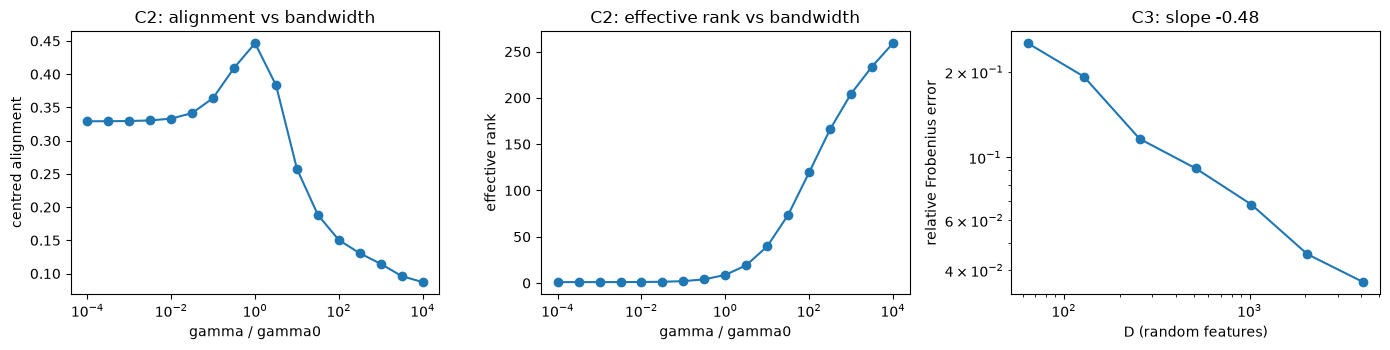

CHECKPOINT 10: concept checks C1-C3 pass.


In [12]:
from sklearn.svm import SVC
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.kernel_approximation import RBFSampler
from scipy.stats import spearmanr

def centered_alignment(K, Y):
    # Cortes et al. centred kernel-target alignment; Y is one-hot (n x c) or +-1 vector
    Y = Y.reshape(len(Y), -1).astype(float); n = len(K); H = np.eye(n) - 1.0 / n
    Kc, Lc = H @ K @ H, H @ (Y @ Y.T) @ H
    den = np.linalg.norm(Kc) * np.linalg.norm(Lc)
    return float((Kc * Lc).sum() / den) if den > 1e-12 else 0.0

def effective_rank(K):
    ev = np.clip(np.linalg.eigvalsh(K), 0, None); p = ev / ev.sum(); p = p[p > 0]
    return float(np.exp(-(p * np.log(p)).sum()))

cds = "unsw_nb15" if "unsw_nb15" in XY else next(d for d in XY if META[d]["kind"] != "image")
rng = np.random.default_rng(GLOBAL_SEED)
idx = rng.choice(len(XY[cds]["train"]["X"]), 600, replace=False)
Xc = XY[cds]["train"]["X"][idx][:, FS[cds]["rank"]["mi"][:8]].astype(np.float64); yc = XY[cds]["train"]["yb"][idx]
Xa, Xb, ya, yb_ = Xc[:400], Xc[400:], yc[:400], yc[400:]
gamma0 = 1.0 / (Xa.shape[1] * Xa.var())
CHECKS = {}

# C1
s1 = SVC(kernel="rbf", gamma=gamma0, C=1.0, tol=1e-10).fit(Xa, ya)
s2 = SVC(kernel="precomputed", C=1.0, tol=1e-10).fit(rbf_kernel(Xa, Xa, gamma=gamma0), ya)
d1, d2 = s1.decision_function(Xb), s2.decision_function(rbf_kernel(Xb, Xa, gamma=gamma0))
c1 = float(np.max(np.abs(d1 - d2)))
CHECKS["C1_precomputed_matches_builtin"] = dict(max_abs_decision_diff=c1, pass_=bool(c1 < 1e-5 and (np.sign(d1) == np.sign(d2)).all()))

# C2
Ypm = np.where(ya == 1, 1.0, -1.0)
gs = gamma0 * np.logspace(-4, 4, 17)
al = [centered_alignment(rbf_kernel(Xa, Xa, gamma=g), Ypm) for g in gs]
er = [effective_rank(rbf_kernel(Xa, Xa, gamma=g)) for g in gs]
peak = int(np.argmax(al)); rho = spearmanr(gs, er).correlation
CHECKS["C2_alignment_peaks_inside_grid"] = dict(peak_gamma_over_gamma0=float(gs[peak] / gamma0), pass_=bool(0 < peak < len(gs) - 1))
CHECKS["C2_effective_rank_rises_with_gamma"] = dict(spearman=float(rho), pass_=bool(rho > 0.9))

# C3
K = rbf_kernel(Xa, Xa, gamma=gamma0); Ds = [64, 128, 256, 512, 1024, 2048, 4096]; errs = []
for D in Ds:
    e = []
    for s in range(5):
        Z = RBFSampler(gamma=gamma0, n_components=D, random_state=s).fit_transform(Xa); e.append(np.linalg.norm(Z @ Z.T - K) / np.linalg.norm(K))
    errs.append(np.mean(e))
slope = float(np.polyfit(np.log(Ds), np.log(errs), 1)[0])
CHECKS["C3_rff_error_slope"] = dict(slope=slope, pass_=bool(-0.7 < slope < -0.3))

for k, v in CHECKS.items():
    print(f"{'PASS' if v['pass_'] else 'FAIL'}  {k}  {({a: round(b, 6) for a, b in v.items() if a != 'pass_'})}")
json.dump(CHECKS, open(RES / "concept_checks_C1_C3.json", "w"), indent=2)

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].semilogx(gs / gamma0, al, "o-"); ax[0].set(xlabel="gamma / gamma0", ylabel="centred alignment", title="C2: alignment vs bandwidth")
    ax[1].semilogx(gs / gamma0, er, "o-"); ax[1].set(xlabel="gamma / gamma0", ylabel="effective rank", title="C2: effective rank vs bandwidth")
    ax[2].loglog(Ds, errs, "o-"); ax[2].set(xlabel="D (random features)", ylabel="relative Frobenius error", title=f"C3: slope {slope:.2f}")
    plt.tight_layout(); plt.savefig(RES / "concept_checks_C2_C3.png", dpi=150); plt.show()
except ImportError:
    pass
assert all(v["pass_"] for v in CHECKS.values()), "A concept check failed: resolve before Phase 1."
print("CHECKPOINT 10: concept checks C1-C3 pass.")

## 11. Classical baselines

**Tasks.** For each dataset: binary and multi-class. For each ordered pair of NetFlow datasets (A → B): binary, trained and tuned on A, tested on B's test split, with A's preprocessing and A's feature ranking.

**Two regimes.**
* *Ceiling*: as much training data as `ceiling_cap` allows (RBF-SVM capped at `svm_cap` because it scales quadratically). This answers "how hard is the task for the best classical model?" and drives the gate.
* *Matched-N*: N ∈ {250, …, 4000} training samples, re-tuned at each N. These are the numbers the quantum kernels will be compared with in Phases 1–4, since quantum kernels are trained on small N.

**Protocol.** Hyperparameters are tuned on the validation split (seed 0) by macro-F1, then each seed redraws the training subset and refits. Class imbalance is handled with balanced class weights.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import matthews_corrcoef, balanced_accuracy_score, roc_auc_score, average_precision_score
import lightgbm as lgb
from joblib import Parallel, delayed

def grid(model, d):
    if model == "lr":   return [dict(C=c) for c in [0.1, 1, 10]]
    if model == "svm":  return [dict(C=c, gm=g) for c in [1, 10] for g in [0.3, 1, 3]]
    if model == "rff":  return [dict(C=c, gm=g) for c in [1, 10] for g in [0.3, 1, 3]]
    if model == "rf":   return [dict(max_depth=m) for m in [None, 20]]
    if model == "xgb":  return [dict(max_depth=m) for m in [6, 10]]
    if model == "lgbm": return [dict(num_leaves=n) for n in [31, 127]]
    if model == "mlp":  return [dict(alpha=a) for a in [1e-4, 1e-3]]

def build(model, hp, seed, Xtr, ytr):
    g0 = 1.0 / (Xtr.shape[1] * max(float(Xtr.var()), 1e-12))
    if model == "lr":   return LogisticRegression(C=hp["C"], class_weight="balanced", max_iter=3000), None
    if model == "svm":  return SVC(C=hp["C"], gamma=hp["gm"] * g0, class_weight="balanced", random_state=seed), None
    if model == "rff":  return Pipeline([("rff", RBFSampler(gamma=hp["gm"] * g0, n_components=1000, random_state=seed)),
                                          ("lr", LogisticRegression(C=hp["C"], class_weight="balanced", max_iter=3000))]), None
    if model == "rf":   return RandomForestClassifier(n_estimators=300, max_depth=hp["max_depth"], class_weight="balanced", n_jobs=1, random_state=seed), None
    if model == "xgb":  return xgb.XGBClassifier(n_estimators=400, max_depth=hp["max_depth"], learning_rate=0.1, tree_method="hist",
                                                 n_jobs=1, random_state=seed), compute_sample_weight("balanced", ytr)
    if model == "lgbm": return lgb.LGBMClassifier(n_estimators=400, num_leaves=hp["num_leaves"], learning_rate=0.05, class_weight="balanced",
                                                  n_jobs=1, random_state=seed, verbose=-1), None
    if model == "mlp":  return MLPClassifier(hidden_layer_sizes=(128, 64), alpha=hp["alpha"], early_stopping=True, max_iter=300, random_state=seed), None


def fast_macro_f1(yt, yp, k):
    cm = np.bincount(yt * k + yp, minlength=k * k).reshape(k, k); tp = np.diag(cm)
    denom = cm.sum(0) + cm.sum(1); present = cm.sum(1) > 0
    f1 = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    return f1[present].mean()

def boot_ci(yt, yp, k, n_boot, seed=0):
    rng = np.random.default_rng(seed); n = len(yt)
    v = [fast_macro_f1(yt[s], yp[s], k) for s in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(v, [2.5, 97.5])

def ece(y, p, bins=15):
    edges = np.linspace(0, 1, bins + 1); b = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return float(sum(abs(y[b == i].mean() - p[b == i].mean()) * (b == i).mean() for i in range(bins) if (b == i).any()))

def scores(mdl, X):
    if hasattr(mdl, "predict_proba"):
        return mdl.predict_proba(X)
    d = mdl.decision_function(X)
    if d.ndim == 1: d = np.c_[-d, d]
    e = np.exp(d - d.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def evaluate(mdl, X, y, k, n_boot, calibrated):
    S = scores(mdl, X); yp = mdl.classes_[np.argmax(S, 1)]
    out = dict(macro_f1=f1_score(y, yp, average="macro", labels=np.unique(y)), mcc=matthews_corrcoef(y, yp),
               bal_acc=balanced_accuracy_score(y, yp))
    if n_boot:
        lo, hi = boot_ci(y, yp.astype(int), k, n_boot); out.update(macro_f1_ci_lo=lo, macro_f1_ci_hi=hi)
    try:
        if k == 2:
            out["roc_auc"] = roc_auc_score(y, S[:, 1])
            minority = int(np.bincount(y, minlength=2).argmin())
            out["minority_pr_auc"] = average_precision_score((y == minority).astype(int), S[:, minority])
            out["ece"] = ece(y, S[:, 1]) if calibrated else np.nan
        else:
            present = np.isin(mdl.classes_, np.unique(y))
            out["roc_auc"] = roc_auc_score(y, S[:, present] / S[:, present].sum(1, keepdims=True), multi_class="ovr",
                                           average="macro", labels=mdl.classes_[present])
    except Exception:
        out["roc_auc"] = np.nan
    return out

def sample_n(y, n, seed, min_per_class=2):
    # proportional stratified sample of size ~n with at least `min_per_class` per class present
    rng = np.random.default_rng(seed); cls, cnt = np.unique(y, return_counts=True)
    if n >= len(y): return rng.permutation(len(y))
    take = np.maximum(np.minimum(cnt, min_per_class), np.round(n * cnt / cnt.sum()).astype(int)); take = np.minimum(take, cnt)
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), t, replace=False) for c, t in zip(cls, take)])
    return rng.permutation(idx)

In [14]:
# Task list
TASKS = []
for ds in SPLITS:
    TASKS.append(dict(task=f"{ds}:binary", src=ds, tgt=ds, label="bin"))
    if META[ds]["kind"] != "image":   # the Fashion-MNIST pair is binary by construction
        TASKS.append(dict(task=f"{ds}:multi", src=ds, tgt=ds, label="multi"))
for a, b in itertools.permutations(NETFLOW_DATASETS, 2):
    TASKS.append(dict(task=f"{a}->{b}:binary", src=a, tgt=b, label="bin"))

def task_arrays(t):
    s, g = t["src"], t["tgt"]
    lab = "yb" if t["label"] == "bin" else "ym"
    tr, va = XY[s]["train"], XY[s]["val"]
    if s == g:
        te_X, te_y = XY[g]["test"]["X"], XY[g]["test"][lab]
    else:  # transform the target's raw test split with the SOURCE pipeline
        te_X = PRE[s]["ct"].transform(SPLITS[g]["test"][PRE[s]["cols"]]).astype(np.float32); te_y = XY[g]["test"][lab]
    classes = np.unique(tr[lab]); enc = {c: i for i, c in enumerate(classes)}
    keep = np.isin(te_y, classes)  # multi-class test rows of classes never seen in training are dropped (and counted)
    f = lambda y: np.array([enc[c] for c in y], dtype=np.int64)
    out = dict(Xtr=tr["X"], ytr=f(tr[lab]), Xva=va["X"], yva=f(va[lab]), Xte=te_X[keep], yte=f(te_y[keep]),
               k=len(classes), dropped_test=int((~keep).sum()), classes=list(map(str, classes)), Xte2=None, yte2=None)
    if s == g and "test_official" in XY[g]:  # UNSW-NB15: also score on the official test file
        X2, y2 = XY[g]["test_official"]["X"], XY[g]["test_official"][lab]; k2 = np.isin(y2, classes)
        out.update(Xte2=X2[k2], yte2=f(y2[k2]))
    return out

ARR = {t["task"]: task_arrays(t) for t in TASKS}
for t in TASKS:
    a = ARR[t["task"]]; print(f"{t['task']:45s} train={len(a['ytr']):>8,} val={len(a['yva']):>7,} test={len(a['yte']):>8,} classes={a['k']}"
                               + (f"  (dropped {a['dropped_test']} unseen-class test rows)" if a["dropped_test"] else ""))

nf_unsw_nb15_v2:binary                        train=  62,412 val= 20,804 test=  20,804 classes=2
nf_unsw_nb15_v2:multi                         train=  62,412 val= 20,804 test=  20,804 classes=10
unsw_nb15:binary                              train=  80,648 val= 20,163 test=  52,639 classes=2
unsw_nb15:multi                               train=  80,648 val= 20,163 test=  52,639 classes=10
fashion_mnist:binary                          train=   9,600 val=  2,400 test=   2,000 classes=2


In [15]:
RESULTS_CSV = RES / "baselines.csv"
done = set()
if RESULTS_CSV.exists():
    prev = pd.read_csv(RESULTS_CSV)
    done = set(zip(prev.task, prev.features, prev.model, prev.regime, prev.n_target, prev.seed))

def run_job(task, fv, model, regime, n_target, Xtr, ytr, Xva, yva, Xte, yte, k, seeds, done, prm, Xte2=None, yte2=None):
    # Self-contained: receives arrays as arguments (joblib memory-maps them) instead of reading globals.
    cap = n_target if regime == "matched" else (prm["svm_cap"] if model == "svm" else prm["ceiling_cap"])
    cap = min(cap, len(ytr))
    iva = sample_n(yva, prm["val_cap"], 0)
    i0 = sample_n(ytr, min(cap, prm["tune_cap"]), 0)  # tune on a capped subset
    best, best_f1 = None, -1.0
    for hp in grid(model, Xtr.shape[1]):
        try:
            mdl, sw = build(model, hp, 0, Xtr[i0], ytr[i0])
            mdl.fit(Xtr[i0], ytr[i0], **({"sample_weight": sw} if sw is not None else {}))
            f = f1_score(yva[iva], mdl.predict(Xva[iva]), average="macro")
            if f > best_f1: best, best_f1 = hp, f
        except Exception:
            continue
    rows = []
    if best is None:
        return [dict(task=task, features=fv, model=model, regime=regime, n_target=n_target, seed=-1, error="all tuning fits failed")]
    for seed in seeds:
        if (task, fv, model, regime, n_target, seed) in done: continue
        idx = sample_n(ytr, cap, seed); t0 = time.time()
        try:
            mdl, sw = build(model, best, seed, Xtr[idx], ytr[idx])
            mdl.fit(Xtr[idx], ytr[idx], **({"sample_weight": sw} if sw is not None else {}))
            ev = evaluate(mdl, Xte, yte, k, prm["n_boot"], calibrated=model != "svm")
            if Xte2 is not None:
                ev2 = evaluate(mdl, Xte2, yte2, k, 0, calibrated=False)
                ev.update({f"official_{m}": ev2[m] for m in ["macro_f1", "mcc", "roc_auc"]})
            rows.append(dict(task=task, features=fv, n_features=Xtr.shape[1], model=model, regime=regime, n_target=n_target,
                             n_train=len(idx), seed=seed, hp=json.dumps(best), val_macro_f1=best_f1,
                             fit_s=round(time.time() - t0, 2), error="", **ev))
        except Exception as e:
            rows.append(dict(task=task, features=fv, model=model, regime=regime, n_target=n_target, seed=seed, error=repr(e)[:200]))
    return rows

RESULT_COLS = ["task", "features", "n_features", "model", "regime", "n_target", "n_train", "seed", "hp", "val_macro_f1", "fit_s",
               "error", "macro_f1", "mcc", "bal_acc", "macro_f1_ci_lo", "macro_f1_ci_hi", "roc_auc", "minority_pr_auc", "ece",
               "official_macro_f1", "official_mcc", "official_roc_auc"]
if RESULTS_CSV.exists():
    assert list(pd.read_csv(RESULTS_CSV, nrows=0).columns) == RESULT_COLS, "baselines.csv has an old column layout: delete it and rerun"
PRM = {k: P[k] for k in ["svm_cap", "ceiling_cap", "val_cap", "n_boot", "tune_cap"]}
t0 = time.time(); n_rows = 0
for t in TASKS:
    a = ARR[t["task"]]
    views = P["image_views"] if META[t["src"]]["kind"] == "image" else P["fs_variants_for_baselines"]
    for fv in views:
        if fv.startswith("ae") and t["src"] not in AE: continue
        view = feature_view(t["src"], t["src"], fv)
        Xtr, Xva, Xte = view(a["Xtr"]), view(a["Xva"]), view(a["Xte"])
        Xte2 = view(a["Xte2"]) if a["Xte2"] is not None else None
        jobs = [(m, "ceiling", P["ceiling_cap"]) for m in MODELS] + [(m, "matched", n) for m in MODELS for n in P["matched_n"]]
        out = Parallel(n_jobs=N_JOBS, backend="loky", max_nbytes="1M")(
            delayed(run_job)(t["task"], fv, m, rg, n, Xtr, a["ytr"], Xva, a["yva"], Xte, a["yte"], a["k"], P["seeds"], done, PRM, Xte2, a["yte2"])
            for m, rg, n in jobs)
        rows = [r for o in out for r in o]
        if rows:
            pd.DataFrame(rows).reindex(columns=RESULT_COLS).to_csv(RESULTS_CSV, mode="a", header=not RESULTS_CSV.exists(), index=False)
            n_rows += len(rows)
        print(f"  {t['task']:45s} {fv:7s} done  ({(time.time() - t0) / 60:.1f} min, {n_rows} rows)")
R_check = pd.read_csv(RESULTS_CSV)
errs = R_check[R_check["error"].fillna("").astype(str).str.len() > 0]
print(f"CHECKPOINT 11: baselines -> {RESULTS_CSV}  ({len(R_check)} rows, {len(errs)} failed runs)")
if len(errs): print(errs[["task", "features", "model", "regime", "n_target", "seed", "error"]].head(20).to_string(index=False))

  nf_unsw_nb15_v2:binary                        all     done  (2.4 min, 420 rows)
  nf_unsw_nb15_v2:binary                        mi8     done  (4.2 min, 840 rows)
  nf_unsw_nb15_v2:binary                        mi12    done  (5.9 min, 1260 rows)
  nf_unsw_nb15_v2:binary                        mi16    done  (8.2 min, 1680 rows)
  nf_unsw_nb15_v2:binary                        mi24    done  (10.6 min, 2100 rows)
  nf_unsw_nb15_v2:binary                        tree8   done  (12.0 min, 2520 rows)
  nf_unsw_nb15_v2:binary                        tree12  done  (13.7 min, 2940 rows)
  nf_unsw_nb15_v2:binary                        tree16  done  (15.7 min, 3360 rows)
  nf_unsw_nb15_v2:binary                        tree24  done  (18.0 min, 3780 rows)
  nf_unsw_nb15_v2:multi                         all     done  (22.9 min, 4200 rows)
  nf_unsw_nb15_v2:multi                         mi8     done  (27.6 min, 4620 rows)
  nf_unsw_nb15_v2:multi                         mi12    done  (32.3 min, 5040 rows

/Users/aakarshetar/Documents/Q-kernel/.kernel/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  nf_unsw_nb15_v2:multi                         tree12  done  (50.5 min, 6720 rows)


/Users/aakarshetar/Documents/Q-kernel/.kernel/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  nf_unsw_nb15_v2:multi                         tree16  done  (55.5 min, 7140 rows)


/Users/aakarshetar/Documents/Q-kernel/.kernel/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


... (35 outputs left out)

/Users/aakarshetar/Documents/Q-kernel/.kernel/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  unsw_nb15:multi                               tree24  done  (310.2 min, 15120 rows)


/Users/aakarshetar/Documents/Q-kernel/.kernel/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  fashion_mnist:binary                          all     done  (319.3 min, 15540 rows)
  fashion_mnist:binary                          pca8    done  (319.9 min, 15960 rows)
  fashion_mnist:binary                          pca12   done  (320.6 min, 16380 rows)
  fashion_mnist:binary                          pca16   done  (321.6 min, 16800 rows)
  fashion_mnist:binary                          pca24   done  (322.5 min, 17220 rows)
CHECKPOINT 11: baselines -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase0/full/baselines.csv  (17220 rows, 0 failed runs)


## 12. Aggregation and the Phase 0 gate

* **Ceiling table:** best model per task (mean macro-F1 over seeds, with the test-bootstrap 95% CI of the median seed).
* **Matched-N table:** best classical macro-F1 at each N — the bar the quantum kernels must be compared against.
* **Gate:** a task has *headroom* if the best ceiling macro-F1 is below 0.95, is *saturated* at 0.98 or above, and *tight* in between. The gate passes when at least two tasks have headroom, the Fashion-MNIST pair is one of them, and concept checks C1–C3 pass.

In [16]:
R = pd.read_csv(RESULTS_CSV)
R = R[R["error"].fillna("").astype(str).str.len() == 0]
agg = (R.groupby(["task", "features", "model", "regime", "n_target"])
         .agg(macro_f1=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"), mcc=("mcc", "mean"), roc_auc=("roc_auc", "mean"),
              minority_pr_auc=("minority_pr_auc", "mean"), ci_lo=("macro_f1_ci_lo", "median"), ci_hi=("macro_f1_ci_hi", "median"),
              seeds=("seed", "nunique"), n_features=("n_features", "first"), n_train=("n_train", "median"))
         .reset_index())
agg.to_csv(RES / "baselines_aggregated.csv", index=False)

ceil = agg[agg.regime == "ceiling"].sort_values("macro_f1", ascending=False).groupby("task").head(1)
def status(f): return "headroom" if f < SATURATION["headroom_below"] else ("saturated" if f >= SATURATION["saturated_at"] else "tight")
ceil = ceil.assign(status=ceil.macro_f1.map(status)).sort_values("task")
ceil.to_csv(RES / "ceiling_best_per_task.csv", index=False)
print("Best classical model per task (ceiling regime):")
print(ceil[["task", "features", "model", "n_train", "macro_f1", "ci_lo", "ci_hi", "mcc", "status"]].round(4).to_string(index=False))

mat = agg[agg.regime == "matched"]
best_n = mat.sort_values("macro_f1", ascending=False).groupby(["task", "n_target"]).head(1).sort_values(["task", "n_target"])
pivot = best_n.pivot_table(index="task", columns="n_target", values="macro_f1").round(4)
pivot.to_csv(RES / "matched_n_best_macro_f1.csv")
print("\nBest classical macro-F1 at matched training size N (the bar for Phases 1-4):")
print(pivot.to_string())

# per-model view at N=4000 (or the largest N run) on the 'all' features: useful for choosing the RBF / RFF controls
nmax = max(P["matched_n"])
print(f"\nPer-model macro-F1 at N={nmax}, all features:")
print(mat[(mat.n_target == nmax) & (mat.features == "all")]
      .pivot_table(index="task", columns="model", values="macro_f1").round(3).to_string())

if "official_macro_f1" in R.columns and R["official_macro_f1"].notna().any():
    u = R[R.task.str.startswith("unsw_nb15:") & (R.regime == "ceiling")]
    cmp_ = (u.groupby(["task", "features", "model"])[["macro_f1", "official_macro_f1"]].mean()
              .assign(inflation=lambda d: d.official_macro_f1 - d.macro_f1).round(4)
              .sort_values("macro_f1", ascending=False).groupby("task").head(3))
    cmp_.to_csv(RES / "unsw_clean_vs_official_test.csv")
    print("\nUNSW-NB15: clean test vs official test (ceiling, top 3 models per task):")
    print(cmp_.to_string())

eligible = ceil
n_head = int((eligible.status == "headroom").sum())
fm_ok = (not USE_FMNIST) or bool((ceil.loc[ceil.task.str.startswith("fashion_mnist"), "status"] == "headroom").any())
gate = dict(mode=MODE, tasks_with_headroom=list(eligible.loc[eligible.status == "headroom", "task"]),
            saturated_tasks_to_drop=list(ceil.loc[ceil.status == "saturated", "task"]),
            concept_checks_pass=all(v["pass_"] for v in CHECKS.values()), feature_variant=VARIANT,
            fashion_mnist_has_headroom=fm_ok,
            gate_pass=bool(n_head >= 2 and fm_ok and all(v["pass_"] for v in CHECKS.values())))
json.dump(gate, open(RES / "phase0_gate.json", "w"), indent=2)
print("\n" + "=" * 70)
print(f"PHASE 0 GATE ({MODE}): {'PASS' if gate['gate_pass'] else 'NOT YET'}")
print(json.dumps(gate, indent=1))
if MODE == "smoke":
    print("\nSmoke mode uses synthetic data: the verdict only proves the pipeline runs. Switch MODE to 'quick'.")

Best classical model per task (ceiling regime):
                  task features model  n_train  macro_f1  ci_lo  ci_hi    mcc   status
  fashion_mnist:binary      all   xgb   9600.0    0.8759 0.8609 0.8904 0.7527 headroom
nf_unsw_nb15_v2:binary      all   xgb  62412.0    0.9393 0.9358 0.9427 0.8807 headroom
 nf_unsw_nb15_v2:multi      all   xgb  62412.0    0.6608 0.6257 0.6868 0.8102 headroom
      unsw_nb15:binary      all  lgbm  80648.0    0.8259 0.8229 0.8293 0.6924 headroom
       unsw_nb15:multi      all  lgbm  80648.0    0.6108 0.5942 0.6255 0.6354 headroom

Best classical macro-F1 at matched training size N (the bar for Phases 1-4):
n_target                  250     500     1000    2000    4000
task                                                          
fashion_mnist:binary    0.8118  0.8261  0.8383  0.8513  0.8589
nf_unsw_nb15_v2:binary  0.9159  0.9168  0.9244  0.9285  0.9310
nf_unsw_nb15_v2:multi   0.3511  0.3719  0.4050  0.4605  0.5027
unsw_nb15:binary        0.7668  0.781

## What to send back before Phase 1

From `results/phase0/<mode>/`:
1. The printed output of Sections 2–6 (hash checks, counts, dedup tables, UNSW overlap, splits).
2. `leakage_single_feature_probes.csv` (top 10 rows per dataset) and `leakage_ttl_ablation.csv`.
3. `ceiling_best_per_task.csv`, `matched_n_best_macro_f1.csv`, `unsw_clean_vs_official_test.csv` and `fashion_mnist_pair.json`.
4. `phase0_gate.json`.

Phase 1 reads `data/processed/<dataset>/{train,val,test}_<mode>.parquet`, the saved preprocessors, `pca_<mode>.joblib` (Fashion-MNIST) and `feature_rankings.json`, so nothing here needs to be recomputed.